## Homework 1: VQGAN Transformer

Мы привыкли, что для работы с изображениями нужны сверточные сети. Но картинку можно превратить в последовательность токенов и скормить классическому GPT точно так же, как текст.

Первыми эту идею стали использовать в **[ImageGPT](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)**. Цвета пикселей кластеризовали алгоритмом K-Means и получили некоторый словарь оттенков. Дальше авторы просто обучали обычный GPT предсказывать цвет следующего пикселя. Но такой подход быстро уперся в проблему с вычислениями, поскольку даже небольшой размер картинки $32\times32$ требуют генерации больше тысячи токенов.

Авторы **[VQGAN](https://arxiv.org/abs/2012.09841)** нашли более изящное решение. Вместо того чтобы квантовать пиксели напрямую, они сначала обучают VQ-VAE, который сжимает картинку в компактную сетку токенов, например $16\times16$. Уже поверх этой короткой последовательности учится тот же авторегрессионный трансформер, только теперь каждый токен несёт на порядки больше смысла.

### Задание
В этой работе мы попробуем реализовать рецепт из статьи VQGAN и обучить GPT для генерации картинок. Обучать свой VQ-VAE нам не придется, поскольку это потребует значительных ресурсов. Вместо этого мы будем использовать предобученную модель, с помощью которой закодируем наш датасет, и обучим поверх полученных токенов трансформер.

За выполнение домашнего задания можно получить до **10 баллов**.

In [1]:
import os
import json
import math
import random
import time
from pathlib import Path

run_dir = Path("hw1_pro_runs")
run_dir.mkdir(exist_ok=True)
os.environ["HF_HOME"] = str(run_dir / "hf_cache")
os.environ["HF_HUB_DISABLE_XET"] = "1"

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from diffusers import VQModel
from IPython.display import clear_output
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms
from tqdm.auto import tqdm

Matplotlib is building the font cache; this may take a moment.


/Users/ninachely/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/ninachely/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(8)
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

In [4]:
print(f"Using device: {device}")

Using device: mps


### Задание 1: Dataset (0.5 балла)

Для обучения нашей модели мы будем использовать датасет `Imagenette` — уменьшенную версию ImageNet из 10 классов c  $\sim 950$ фотографиями на класс.

Датасет уже разбит на `train` и `val`. Мы возьмём вариант с `size="160px"`, этого с запасом хватит для наших целей.

In [5]:
from torchvision.datasets import Imagenette

Картинки тут не фиксированного размера, поэтому перед подачей в модель их нужно обрезать:

- Создайте преобразования `transforms` для обучающего (`train_dataset`) — `Resize(144)`, `RandomCrop(128)` и `RandomHorizontalFlip`.
- Для валидационного (`val_dataset`) — `Resize(144)` и `CenterCrop(128)`.
- Загрузите Imagenette (`size="160px"`) с соответствующими преобразованиями
- Создайте DataLoaders для каждого датасета

In [6]:
# Some images are grayscale (mode "L"), not RGB - convert them explicitly.
to_rgb = transforms.Lambda(lambda img: img.convert("RGB"))

In [7]:
# Train transform: Resize(144), RandomCrop(128), RandomHorizontalFlip, ToTensor
train_transform = transforms.Compose([to_rgb, transforms.Resize(144), transforms.RandomCrop(128), transforms.RandomHorizontalFlip(), transforms.ToTensor()])

In [8]:
# Val transform: same Resize(144) + CenterCrop(128), but no augmentations
val_transform = transforms.Compose([to_rgb, transforms.Resize(144), transforms.CenterCrop(128), transforms.ToTensor()])

In [9]:
data_dir = run_dir / "data"
train_dataset = Imagenette(data_dir, split="train", size="160px", transform=train_transform, download=not (data_dir / "imagenette2-160").exists())
val_dataset = Imagenette(data_dir, split="val", size="160px", transform=val_transform)

In [10]:
# Human-readable class names - train_dataset.classes is a list of synonym tuples
mappings = {i: names[0] for i, names in enumerate(train_dataset.classes)}

In [11]:
batch_size = 32
num_workers = 0
to_use_pin_memory = False

In [12]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=to_use_pin_memory)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=to_use_pin_memory)

In [13]:
print(f"Train: {len(train_dataset)}, validation: {len(val_dataset)}, classes: {len(mappings)}")
print(mappings)

Train: 9469, validation: 3925, classes: 10
{0: 'tench', 1: 'English springer', 2: 'cassette player', 3: 'chain saw', 4: 'church', 5: 'French horn', 6: 'garbage truck', 7: 'gas pump', 8: 'golf ball', 9: 'parachute'}


Прежде чем приступить к построению модели всегда полезно взглянуть на данные, с которыми предстоит работать. Это даёт общее представление о данных и позволяет убедиться, что всё загрузилось корректно.

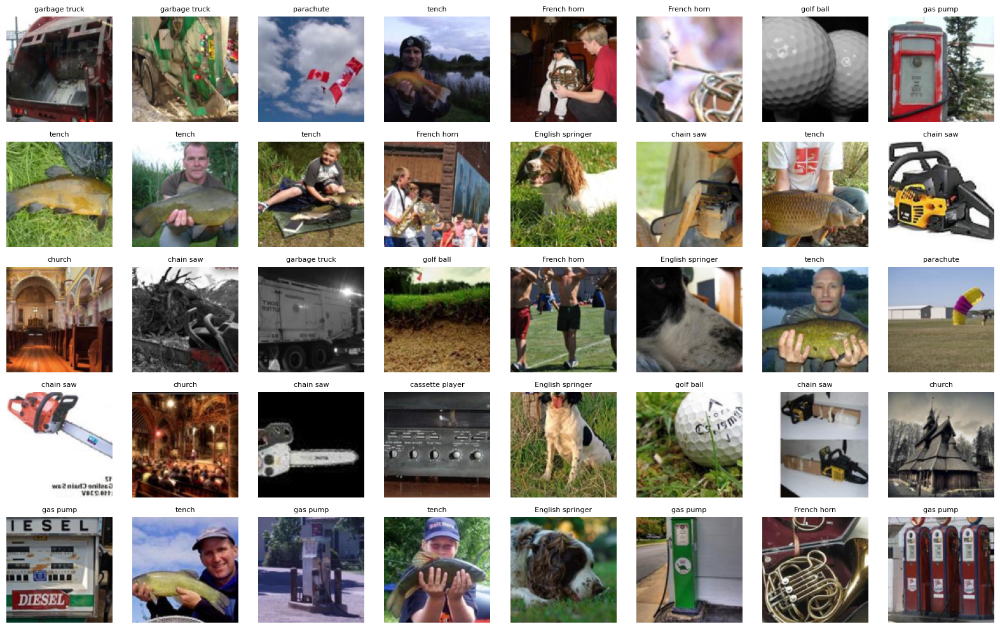

In [14]:
# Select a random set of indices from the training dataset.
indices = torch.randperm(len(train_dataset))[:40]

fig, axes = plt.subplots(5, 8, figsize=(16, 10))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[indices[i]]  

    image = image.permute(1, 2, 0).cpu().numpy()

    ax.imshow(image)
    ax.axis('off')
    ax.set_title(f"{mappings[label]}", fontsize=8)

plt.tight_layout()
plt.show()

### Задание 2: Предобученный VQ-VAE (1.5 балла)

Чтобы получить латентную сетку токенов из картинки, мы будем использовать VQ-VAE, который состоит из 3 частей:

- **Encoder** сжимает картинку в сетку непрерывных векторов.
- **Vector Quantizer** заменяет каждый вектор на ближайший вектор из обучаемого словаря (codebook).
- **Decoder** восстанавливает картинку обратно по этой квантованной сетке.

<center><img src="images/vq-vae.png" width=700></center>

Обучить хороший VQ-VAE с нуля непросто. Поэтому мы возьмём предобученный VQ-VAE из библиотеки `diffusers` (`microsoft/vq-diffusion-ithq`) и будем использовать его только для кодирования и декодирования картинок.

На что стоит обратить внимание:

- модель уменьшает разрешение в 8 раз
- размер codebook (`num_vq_embeddings`) — 4096 векторов
- вход нормализован в $[-1, 1]$, а не в $[0, 1]$, как отдаёт `ToTensor()`

Для наших картинок $128\times128$ это даёт латентную сетку $16\times16$, то есть $256$ токенов.

In [15]:
vqvae = VQModel.from_pretrained("microsoft/vq-diffusion-ithq", subfolder="vqvae")
vqvae.to(device)
vqvae.eval()

for p in vqvae.parameters():
    p.requires_grad = False

An error occurred while trying to fetch microsoft/vq-diffusion-ithq: microsoft/vq-diffusion-ithq does not appear to have a file named diffusion_pytorch_model.safetensors.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


In [16]:
print(f"Codebook size: {vqvae.config.num_vq_embeddings}")

Codebook size: 4096


Дальше нам нужно научиться переводить картинку в латентные токены и обратно. Для этого реализуйте 3 функции:

- **`img_to_codes`**: кодирует картинку в сетку индексов нашего словаря

- **`codes_to_img`**: восстанавливает картинку по сетке индексов

- **`img_to_seq`**: преобразует двумерную сетку латентных токенов $16\times16$ в одномерную последовательность.

In [17]:
@torch.no_grad()
def img_to_codes(x, vqvae):
    # x: [B, 3, H, W] in [0, 1] range (as returned by ToTensor())

    # Rescale x to [-1, 1], the range VQModel is trained on
    x = x * 2 - 1

    # Get the continuous encoder latents
    latent = vqvae.encode(x).latents

    # Quantize the latents and get the indices of the nearest codebook vectors
    indices = vqvae.quantize(latent)[2][2]

    b, _, h, w = latent.shape
    return indices.view(b, h, w)


@torch.no_grad()
def codes_to_img(codes, vqvae):
    # codes: [B, H, W] long - indices into the codebook
    b, h, w = codes.shape
    flat_codes = codes.reshape(-1)

    # Look up codebook vectors by index (use vqvae.quantize.get_codebook_entry)
    quant = vqvae.quantize.get_codebook_entry(flat_codes, shape=(b, h, w, vqvae.config.vq_embed_dim))

    # Run through vqvae.decode
    dec = vqvae.decode(quant, force_not_quantize=True).sample

    return ((dec + 1) / 2).clamp(0, 1)  # back to [0, 1] for display

In [18]:
def img_to_seq(x):
    # x: [batch_size, H, W] -> [batch_size, H * W]
    # Flatten the token grid into a row
    b, h, w = x.shape

    return x.reshape(b, h * w)

In [19]:
def plot_reconstructions(vqvae, val_loader, device, n=8):
    images, _ = next(iter(val_loader))
    images = images[:n].to(device)
    with torch.no_grad():
        codes = img_to_codes(images, vqvae)
        recon = codes_to_img(codes, vqvae)

    originals = images.permute(0, 2, 3, 1).cpu().numpy()
    recons = recon.permute(0, 2, 3, 1).clamp(0, 1).cpu().numpy()

    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4))
    for i in range(n):
        axes[0, i].imshow(originals[i])
        axes[1, i].imshow(recons[i])

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    axes[0, 0].set_ylabel("original")
    axes[1, 0].set_ylabel("recon")
    plt.tight_layout()
    plt.show()

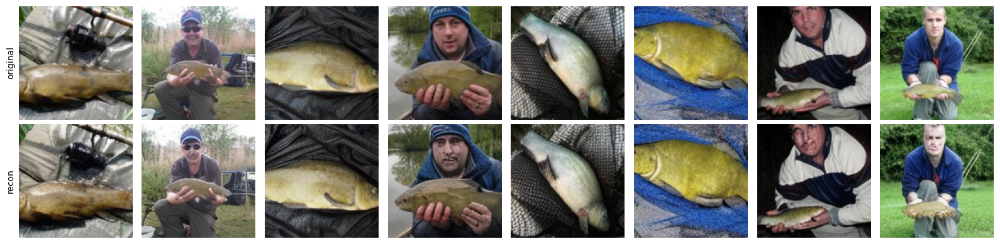

In [20]:
plot_reconstructions(vqvae, val_loader, device)

In [21]:
images, labels = next(iter(val_loader))
codes = img_to_codes(images[:2].to(device), vqvae)
reconstructed = codes_to_img(codes, vqvae)
assert codes.shape == (2, 16, 16)
assert reconstructed.shape == (2, 3, 128, 128)
assert codes.min() >= 0 and codes.max() < vqvae.config.num_vq_embeddings
assert torch.isfinite(reconstructed).all()

In [22]:
print(f"Image: {tuple(images[:2].shape)}, codes: {tuple(codes.shape)}, sequence: {tuple(img_to_seq(codes).shape)}")

Image: (2, 3, 128, 128), codes: (2, 16, 16), sequence: (2, 256)


### Задание 3: Embeddings (1.5 балла)

Чтобы трансформер мог работать с изображениями, их нужно преобразовать в понятный для него формат. В текстовых моделях слова сначала превращаются в  токены, а затем — в вектора эмбеддингов, в которых хранится "смысл слов".

С изображениями мы поступаем так же, но вместо слов мы работаем с токенами VQ-VAE. Их превращают в векторы, которые в процессе обучения постепенно учатся отражать некоторые связи между токенами помогают модели улавливать контекст изображения.

В ImageGPT нам потребуются несколько типов эмбеддингов для кодирования входных изображений:

- **`token_embeddings`**: преобразуют индексы латентных токенов в вектора

- **`position_embeddings`**: кодируют информацию о позиции каждого токена в последовательности, это позволяет модели улавливать пространственные отношения между ними

- **`class_embedding`**: преобразует индекс класса в вектор и выступает в роли условного стартового токена, который сообщает модели, изображение какого именно класса нужно генерировать

In [23]:
class GPTEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_dim, max_positions, num_classes):
        super().__init__()
        self.token_embeddings = nn.Embedding(vocab_size, embed_dim)
        self.position_embeddings = nn.Embedding(max_positions, embed_dim)
        self.class_embedding = nn.Embedding(num_classes, embed_dim)

    def forward(self, x, cls_label):
        # x: [batch_size, seq_len], cls_label: [batch_size]

        tok_emb = self.token_embeddings(x)  
        cls_token_emb = self.class_embedding(cls_label).unsqueeze(1)

        # Prepend the class embedding to the start of the sequence
        full_seq = torch.cat([cls_token_emb, tok_emb], dim=1)  # [batch_size, seq_len + 1, embed_dim]

        # Positional embeddings for the resulting length, with a batch axis for broadcasting
        pos_ids = torch.arange(full_seq.size(1), device=x.device)  # [seq_len + 1]
        pos_emb = self.position_embeddings(pos_ids).unsqueeze(0)  # [1, seq_len + 1, embed_dim]

        embeddings = full_seq + pos_emb  # [batch_size, seq_len + 1, embed_dim]

        return embeddings

### Задание 4: Decoder Block (1.5 балла)

Теперь нам нужно собрать основные блоки нашей модели — блоки декодера. В каждом таком блоке последовательно выполняются следующие операции:

- **`LayerNorm`**
- **`MultiHeadAttention`**
- **`Residual Connection`**
- **`LayerNorm`**
- **`MLP`**:
  - **Linear**: $embed\; dim$ -> $4 \times embed\; dim$
  - **GELU Activation**
  - **Linear**: $(4 \times embed\; dim)$ -> $embed\; dim$
- **`Residual Connection`**

Поскольку наша модель является генеративной и предсказывает следующий элемент в последовательности, вам потребуется использовать **Masked Self-Attention**. Сама маска зависит только от длины последовательности, поэтому блок не строит её сам, а получает готовой аргументом `attn_mask` (её создаст `ImageGPT` в Задании 5).

Вы можете воспользоваться готовой реализацией **Multi-Head Attention** из PyTorch.

In [24]:
class DecoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True,  # our batch format is [batch_size, seq_len, embed_dim]
        )
        self.ln2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(nn.Linear(embed_dim, 4 * embed_dim), nn.GELU(), nn.Linear(4 * embed_dim, embed_dim))

    def forward(self, x, attn_mask):
        # x: [batch_size, seq_len + 1, embed_dim]
        # attn_mask: [seq_len + 1, seq_len + 1] - ready-made causal mask, built by ImageGPT

        # 1. LayerNorm + Masked Multi-Head Attention + Residual
        residual = x
        x = self.ln1(x)

        attn_output, _ = self.attn(x, x, x, attn_mask=attn_mask, need_weights=False)
        x = residual + attn_output

        # 2. LayerNorm + MLP + Residual
        residual = x
        x = self.ln2(x)
        mlp_output = self.mlp(x)
        x = residual + mlp_output

        return x

### Задание 5: Final Model (1 балл)

Теперь, когда у нас есть все компоненты, мы можем собрать их вместе, чтобы построить итоговую модель ImageGPT.

Итоговая архитектура выглядит так:

- **`Embedding`**: преобразует входные токены в векторы

- **`Blocks`**: использует `num_layers` блоков `DecoderBlock`, которые последовательно обрабатывают наши данные

- **`Final LayerNorm`**: нормализует выходные данные перед финальным предсказанием

- **`Head`**: преобразует обработанные векторы в предсказания

Здесь же создайте causal-маску на максимальную длину последовательности и положите её в буфер модели. В `forward` от неё достаточно отрезать кусок под текущую длину и передать во все блоки, так она построится один раз, а не заново в каждом блоке на каждом форварде.

Обратите внимание, что `ImageGPT` работает только с индексами токенов в словаре и ничего не знает о цвете — за декодирование обратно в картинку отвечает загруженный ранее `vqvae` (см. Задание 2).

In [25]:
class ImageGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_heads, num_layers, max_positions, num_classes):
        super().__init__()
        self.embedding = GPTEmbedding(vocab_size, embed_dim, max_positions, num_classes)
        self.blocks = nn.ModuleList([DecoderBlock(embed_dim, num_heads) for _ in range(num_layers)])  # nn.ModuleList of num_layers DecoderBlock
        self.ln_f = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, vocab_size, bias=False)  # nn.Linear without bias, embed_dim -> vocab_size

        # Causal mask built once for the max sequence length and stored as a buffer
        causal_mask = torch.triu(torch.ones(max_positions, max_positions, dtype=torch.bool), diagonal=1)
        self.register_buffer("causal_mask", causal_mask, persistent=False)

    def forward(self, x, y):
        # x: [batch_size, seq_len], y: [batch_size]

        h = self.embedding(x, y)  # [batch_size, seq_len + 1, embed_dim]

        # Slice the mask down to the current sequence length
        seq_len = h.size(1)
        attn_mask = self.causal_mask[:seq_len, :seq_len]

        for block in self.blocks:
            h = block(h, attn_mask)

        h = self.ln_f(h)  # final LayerNorm
        output = self.head(h)  # project to vocabulary logits

        return output

In [26]:
model_config = dict(
    embed_dim=256,
    num_heads=8,
    num_layers=8,
    max_positions=16 * 16,
    vocab_size=vqvae.config.num_vq_embeddings,
    num_classes=10,
)
model = ImageGPT(**model_config).to(device)
total_params = sum(p.numel() for p in model.parameters())

In [27]:
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 8,483,840


In [28]:
model.eval()
x_check = torch.randint(0, model_config["vocab_size"], (2, 15), device=device)
y_check = torch.tensor([0, 1], device=device)
x_changed = x_check.clone()
x_changed[:, 7:] = (x_changed[:, 7:] + 1) % model_config["vocab_size"]
with torch.no_grad():
    logits_check = model(x_check, y_check)
    logits_changed = model(x_changed, y_check)
assert logits_check.shape == (2, 16, 4096)
assert torch.allclose(logits_check[:, :8], logits_changed[:, :8], atol=1e-5)
assert not torch.allclose(logits_check[:, 8:], logits_changed[:, 8:])

In [29]:
print("Causal mask: changing future tokens does not affect earlier predictions")

Causal mask: changing future tokens does not affect earlier predictions


### Задание 6: Sampling (1.5 балла)

Для генерации новых изображений мы будем использовать уже обученную модель ImageGPT. Давайте напишем функцию **`sample`**, которая будет отвечать за это.

Она будет принимать на вход следующие параметры:

- **`model`**: наша обученная модель ImageGPT.

- **`length`**: число шагов генерации

- **`context`**: начальная последовательность латентных токенов, если мы хотим дорисовать изображение. Если её нет, генерация начнётся с нуля.

- **`class_label`**: метка класса для генерации по заданному условию

- **`temperature`**: параметр, который регулирует уровень случайности при генерации

- **`num_samples`**: количество изображений, которые нужно сгенерировать

- **`top_k`**: количество самых вероятных токенов, которые будут использоваться при генерации

- **`device`**: устройство, на котором будет происходить генерация, по умолчанию берётся то, на котором лежит модель

In [30]:
def sample(model, length, class_label, num_samples=1, device=None,
           context=None, temperature=1.0, top_k=None):

    if device is None:
        device = next(model.parameters()).device

    # Expand the class label so every generated image gets its own
    class_label = torch.as_tensor(class_label, device=device, dtype=torch.long).reshape(-1).expand(num_samples)  # [num_samples]

    if context is None or context.numel() == 0:
        context = torch.empty(num_samples, 0, device=device, dtype=torch.long)  # [num_samples, 0]
    else:
        if context.dim() == 1:
            context = context.unsqueeze(0)  # add a batch axis: [1, context_len]
        context = context.to(device=device, dtype=torch.long).expand(num_samples, -1).clone()  # repeat the context num_samples times: [num_samples, context_len]

    model.eval()
    generated = context  # [num_samples, context_len]

    with torch.no_grad():
        for _ in range(length):
            logits = model(generated, class_label)  # [num_samples, context_len + 1, vocab_size]

            # Logits for the next token (last position of the model output)
            next_token_logits = logits[:, -1, :] / temperature  # [num_samples, vocab_size]

            if top_k is not None:
                top_values, _ = torch.topk(next_token_logits, min(top_k, next_token_logits.size(-1)), dim=-1)
                threshold = top_values[:, -1:]
                next_token_logits = next_token_logits.masked_fill(next_token_logits < threshold, -torch.inf)

            probs = torch.softmax(next_token_logits, dim=-1) 
            next_tokens = torch.multinomial(probs, num_samples=1)

            generated = torch.cat([generated, next_tokens], dim=1)

    return generated

In [31]:
sample_check = sample(model, length=3, class_label=0, num_samples=2, context=x_check[0, :5], top_k=1)
assert sample_check.shape == (2, 8)
assert torch.equal(sample_check[:, :5], x_check[0, :5].expand(2, -1))
assert torch.equal(sample_check[0], sample_check[1])
empty_check = sample(model, length=1, class_label=torch.tensor([0, 1]), num_samples=2)
assert empty_check.shape == (2, 1)

In [32]:
print("Sampling: prefix is preserved, class-only generation works, top_k=1 is deterministic")

Sampling: prefix is preserved, class-only generation works, top_k=1 is deterministic


### Задание 7: Training and Validation Loop (1.5 балла)

После того как все компоненты модели собраны, мы можем приступить к обучению. Вам нужно реализовать три функции:

- **`compute_loss`**: кодирует батч картинок в токены и считает по ним ошибку.

- **`train_one_epoch`**: проходит одну эпоху по обучающей выборке

- **`validate_one_epoch`**: роходит одну эпоху по валидационной выборке

Функции **`save_checkpoint`** и **`plot_losses`** уже написаны, они сохраняют веса и рисуют график лоссов по эпохам.

In [33]:
def compute_loss(model, vqvae, images, labels, criterion):
    with torch.no_grad():
        encoding_indices = img_to_codes(images, vqvae) if images.ndim == 4 else images.reshape(-1, 16, 16)  # [batch_size, 16, 16]
        tokens = img_to_seq(encoding_indices).long()  # [batch_size, 256]

    logits = model(tokens[:, :-1], labels)

    return criterion(logits.reshape(-1, logits.size(-1)), tokens.reshape(-1))

In [34]:
def train_one_epoch(model, vqvae, train_loader, optimizer, criterion, scheduler, device):

    model.train()
    total_loss = 0.0

    for images, labels in tqdm(train_loader, desc="Train", leave=False, mininterval=30):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        loss = compute_loss(model, vqvae, images, labels, criterion)
        loss.backward()  # backward, optimizer step, zero the gradients, and step the scheduler (if any)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if scheduler is not None:
            scheduler.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(train_loader.dataset)

In [35]:
def validate_one_epoch(model, vqvae, val_loader, criterion, device):

    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Val", leave=False, mininterval=30):
            images = images.to(device)
            labels = labels.to(device)

            total_loss += compute_loss(model, vqvae, images, labels, criterion).item() * images.size(0)

    return total_loss / len(val_loader.dataset)

In [36]:
def save_checkpoint(model, save_path):
    save_dir = os.path.dirname(save_path)
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)

    torch.save(model.state_dict(), save_path)

In [37]:
def plot_losses(train_losses, val_losses):
    clear_output()
    plt.figure(figsize=(6, 4))
    plt.plot(train_losses, label="Train Loss")
    plt.plot(val_losses, label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

In [38]:
@torch.no_grad()
def cache_tokens(dataset, split, view):
    path = run_dir / f"{split}_tokens_{view}.pt"
    if path.exists():
        return torch.load(path, map_location="cpu", weights_only=True)
    torch.manual_seed(seed + view)
    loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)
    all_tokens, all_labels = [], []
    for images, labels in tqdm(loader, desc=f"Encode {split} {view}", mininterval=30):
        tokens = img_to_seq(img_to_codes(images.to(device), vqvae))
        all_tokens.append(tokens.cpu().to(torch.int16))
        all_labels.append(labels)
    result = {"tokens": torch.cat(all_tokens), "labels": torch.cat(all_labels)}
    torch.save(result, path)
    return result

In [39]:
train_cache = [cache_tokens(train_dataset, "train", view) for view in range(3)]
val_cache = cache_tokens(val_dataset, "val", 0)

In [40]:
class CachedTokens(Dataset):
    def __init__(self, views):
        self.tokens = torch.stack([view["tokens"] for view in views])
        self.labels = views[0]["labels"]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        view = torch.randint(self.tokens.size(0), ()).item()
        return self.tokens[view, index].long(), self.labels[index]

In [41]:
train_token_dataset = CachedTokens(train_cache)
val_token_dataset = TensorDataset(val_cache["tokens"].long(), val_cache["labels"])
train_token_loader = DataLoader(train_token_dataset, batch_size=32, shuffle=True, num_workers=0)
val_token_loader = DataLoader(val_token_dataset, batch_size=32, shuffle=False, num_workers=0)
assert len(train_token_dataset) == len(train_dataset)
assert len(val_token_dataset) == len(val_dataset)
assert all(torch.equal(view["labels"], train_cache[0]["labels"]) for view in train_cache)
assert not torch.equal(train_cache[0]["tokens"], train_cache[1]["tokens"])
assert torch.equal(img_to_seq(codes).cpu(), val_cache["tokens"][:2].long())

In [42]:
print("Train tokens:", tuple(train_token_dataset.tokens.shape), "validation tokens:", tuple(val_cache["tokens"].shape))

Train tokens: (3, 9469, 256) validation tokens: (3925, 256)


Для визуализации результатов работы нашей модели нам потребуется несколько вспомогательных функций. Ниже представлены некоторые функции, которые помогут нам подготовить данные, запустить процесс генерации и сравнить сгенерированные изображения с оригиналом.

In [43]:
def pick_val_sample(val_loader, device):
    img_sample, class_sample = next(iter(val_loader))
    img_sample = img_sample[0:1].to(device)
    class_sample = class_sample[0:1].to(device)
    return img_sample, class_sample

In [44]:
def generate_image_tokens(model, class_sample, h, w, device, top_k=None):
    gen_seq = sample(
        model,
        context=None,
        class_label=class_sample,
        length=h * w,
        device=device,
        top_k=top_k
    )  # [1, h * w]
    return gen_seq.squeeze(0)  # [h * w]

In [45]:
def image_to_tokens(image_tensor, vqvae):
    with torch.no_grad():
        encoding_indices = img_to_codes(image_tensor, vqvae)  # [1, h, w]
    return encoding_indices.reshape(-1)  # [h * w]

In [46]:
def tokens_to_image(tokens, h, w, vqvae):
    tokens = tokens.reshape(1, h, w).to(next(vqvae.parameters()).device)
    with torch.no_grad():
        rgb_image = codes_to_img(tokens, vqvae).clamp(0, 1)  # [1, 3, 128, 128]

    rgb_image = (rgb_image[0] * 255).to(torch.uint8)  # [3, 128, 128]

    return rgb_image.permute(1, 2, 0).cpu().numpy()  # [128, 128, 3]

In [47]:
def plot_generated_vs_original(gen_img_rgb, original_img_rgb, class_label):
    final_img = np.concatenate([gen_img_rgb, original_img_rgb], axis=1)
    plt.figure(figsize=(4, 2))
    plt.title(f"Generated vs Original – Class {mappings[class_label]}")
    plt.imshow(final_img)
    plt.axis("off")
    plt.show()

In [48]:
def generate_and_plot_sample(model, vqvae, val_loader, device, top_k=None):
    model.eval()
    img_sample, class_sample = pick_val_sample(val_loader, device)

    with torch.no_grad():
        codes = img_to_codes(img_sample, vqvae)  # [1, h, w]
    h, w = codes.shape[1], codes.shape[2]
    original_tokens = codes.reshape(-1)  # [h * w]

    gen_seq = generate_image_tokens(model, class_sample, h, w, device, top_k)
    generated_image_rgb = tokens_to_image(gen_seq, h, w, vqvae)
    original_image_rgb = tokens_to_image(original_tokens, h, w, vqvae)
    
    plot_generated_vs_original(generated_image_rgb, original_image_rgb, class_sample.item())

In [49]:
def train_imagegpt(model, vqvae, train_loader, val_loader, optimizer, criterion,
                   scheduler, checkpoint_dir, device=device, epochs=30):
    model.to(device)
    vqvae.eval()
    train_loss_history, val_loss_history = [], []
    epoch_seconds = []
    for epoch in tqdm(range(epochs), desc="Epochs", mininterval=30):
        started = time.perf_counter()
        train_loss = train_one_epoch(model, vqvae, train_loader, optimizer, criterion, scheduler, device)
        val_loss = validate_one_epoch(model, vqvae, val_loader, criterion, device)
        train_loss_history.append(train_loss)
        val_loss_history.append(val_loss)
        epoch_seconds.append(time.perf_counter() - started)
        save_checkpoint(model, f"{checkpoint_dir}/imagegpt_last.pt")
        if val_loss <= min(val_loss_history):
            save_checkpoint(model, f"{checkpoint_dir}/imagegpt_selected.pt")
        history = {"train": train_loss_history, "val": val_loss_history, "seconds": epoch_seconds}
        with open(run_dir / "history.json", "w") as f:
            json.dump(history, f)
        torch.save({"epoch": epoch + 1, "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "config": model_config,
                    "history": history, "seed": seed, "device": str(device)},
                   f"{checkpoint_dir}/training_state.pt")
        # you can comment this out if you don't want to generate samples after every epoch
    return history

Теперь мы готовы запустить основной цикл обучения. Вы можете экспериментировать с различными гиперпараметрами и расписанием обучения, чтобы добиться хороших результатов.

In [50]:
epochs = 30
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)
steps = epochs * len(train_token_loader)
warmup_steps = 2 * len(train_token_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: (step + 1) / warmup_steps if step < warmup_steps else
    0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / (steps - warmup_steps))),
)
checkpoint_dir = str(run_dir / "checkpoints")
with open(run_dir / "config.json", "w") as f:
    json.dump({"model": model_config, "epochs": epochs, "batch_size": 32,
               "lr": 3e-4, "weight_decay": 0.01, "seed": seed, "device": str(device)}, f, indent=2)

In [51]:
torch.manual_seed(seed)
history = train_imagegpt(
    model, vqvae, train_token_loader, val_token_loader, optimizer,
    criterion, scheduler, checkpoint_dir, device=device, epochs=epochs,
)

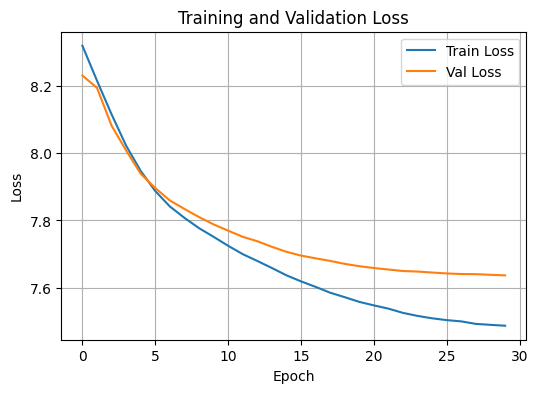

In [52]:
plot_losses(history["train"], history["val"])

In [53]:
print(f"Epochs completed: {len(history['train'])}")
print(f"Train CE: {history['train'][0]:.4f} -> {history['train'][-1]:.4f}")
print(f"Validation CE: {history['val'][0]:.4f} -> {history['val'][-1]:.4f}")
print(f"Selected epoch: {np.argmin(history['val']) + 1}")
print(f"Training time: {sum(history['seconds']) / 60:.1f} min")

Epochs completed: 30
Train CE: 8.3198 -> 7.4870
Validation CE: 8.2311 -> 7.6368
Selected epoch: 30
Training time: 32.8 min


После обучения загрузим лучшие по валидации веса, чтобы дальше использовать их для генерации.

In [54]:
checkpoint_file = f"{checkpoint_dir}/imagegpt_selected.pt"
model.load_state_dict(torch.load(checkpoint_file, map_location=device, weights_only=True))
model.eval();

In [55]:
print(f"Model loaded from: {checkpoint_file}")

Model loaded from: hw1_pro_runs/checkpoints/imagegpt_selected.pt


In [56]:
validation_loss = validate_one_epoch(model, vqvae, val_token_loader, criterion, device)
perplexity = math.exp(validation_loss)
token_counts = torch.bincount(train_cache[0]["tokens"].long().flatten(), minlength=4096).float()
unigram_log_probs = ((token_counts + 1) / (token_counts.sum() + 4096)).log()
unigram_loss = -unigram_log_probs[val_cache["tokens"].long()].mean().item()

In [57]:
print(f"Validation CE: {validation_loss:.4f} nats/token")
print(f"Perplexity: {perplexity:.2f}")
print(f"Unigram baseline CE: {unigram_loss:.4f}")
print(f"Uniform baseline CE: {math.log(4096):.4f}")

Validation CE: 7.6368 nats/token
Perplexity: 2073.10
Unigram baseline CE: 8.2242
Uniform baseline CE: 8.3178


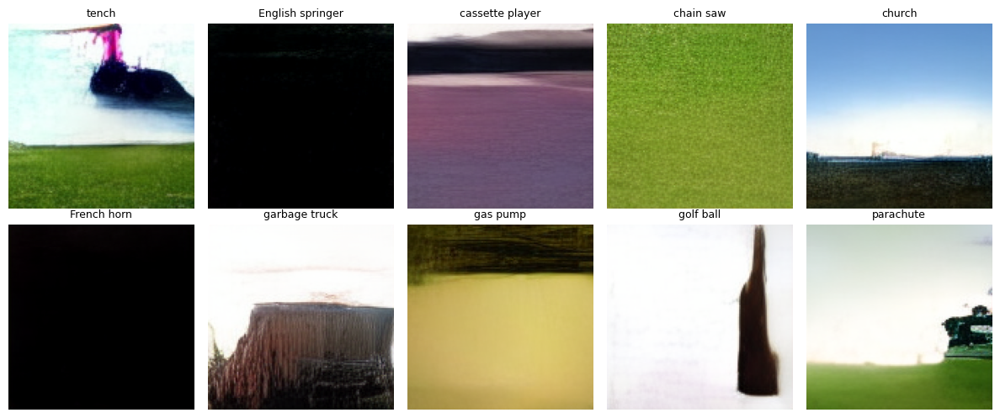

In [58]:
torch.manual_seed(123)
class_tokens = sample(model, length=256, class_label=torch.arange(10, device=device), num_samples=10, temperature=0.9, top_k=500)
class_images = codes_to_img(class_tokens.reshape(10, 16, 16), vqvae).cpu()
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.flat):
    ax.imshow(class_images[label].permute(1, 2, 0))
    ax.set_title(mappings[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Задание 8: Autocompletion (1 балл)

Посмотрим, как модель дорисовывает картинку по началу последовательности токенов. Мы будем давать ей первые `context_size` токенов настоящего изображения и просить сгенерировать все остальные.

Функции для генерации и отрисовки уже написаны, разбираться в их коде необязательно. Главная из них — `generate_and_plot_variations`, именно её нужно запускать с разными параметрами в заданиях 8.1–8.3 ниже.

Каждая строка результата — это один пример из валидации:

- **`context`** (слева): та часть картинки, которую модель получила на вход. Невидимая ей часть закрашена серым.
- **`sample 1..N`**: разные варианты продолжения этого же контекста, отличаются только случайностью сэмплирования.
- **`original`** (справа): как эта картинка выглядит на самом деле.

Обратите внимание, что `original` — это не исходное фото, а его реконструкция через VQ-VAE. Сравнивать генерации честно именно с ней, потому что лучше своего токенизатора модель нарисовать не может.

In [59]:
def pick_val_contexts(val_loader, num_contexts, device, seed=0):
    dataset = val_loader.dataset
    generator = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(dataset), generator=generator)

    context_images, class_labels = [], []
    seen_classes = set()
    with torch.no_grad():
        for idx in perm:
            img, label = dataset[idx.item()]
            if label in seen_classes:
                continue
            seen_classes.add(label)
            context_images.append(img.to(device))
            class_labels.append(torch.tensor(label, device=device))
            if len(context_images) >= num_contexts:
                break
    return context_images, class_labels

def prepare_context(img_tensor, context_size, vqvae):
    original_tokens = image_to_tokens(img_tensor.unsqueeze(0), vqvae)  # [h * w]
    context_tensor = original_tokens[:context_size]
    return context_tensor, original_tokens

def generate_variations(model, vqvae, context_tensor, class_label, h, w, context_size, samples_per_context, temperature=1.0, top_k=None):
    total_tokens = h * w

    gen_seq = sample(model,
                     length=total_tokens - context_size,
                     context=context_tensor,
                     class_label=class_label,
                     num_samples=samples_per_context,
                     temperature=temperature,
                     device=context_tensor.device,
                     top_k=top_k)

    return [tokens_to_image(gen_seq[i], h, w, vqvae) for i in range(samples_per_context)]

def make_context_preview(original_img_rgb, h, w, context_size):
    seen = np.zeros(h * w, dtype=bool)
    seen[:context_size] = True

    scale = original_img_rgb.shape[0] // h
    seen_px = np.repeat(np.repeat(seen.reshape(h, w), scale, axis=0), scale, axis=1)

    preview = original_img_rgb.copy()
    preview[~seen_px] = 128

    return preview

def plot_context_rows(rows_of_images, class_labels):
    num_contexts = len(rows_of_images)
    if num_contexts == 0:
        return
    num_cols = len(rows_of_images[0])
    col_labels = ["context"] + [f"sample {j + 1}" for j in range(num_cols - 2)] + ["original"]

    fig, axs = plt.subplots(nrows=num_contexts, ncols=1, figsize=(num_cols * 2, num_contexts * 2.4))
    if num_contexts == 1: 
        axs = [axs]

    for i, (row, label) in enumerate(zip(rows_of_images, class_labels)):
        combined_row_img = np.concatenate(row, axis=1)
        axs[i].imshow(combined_row_img)
        axs[i].set_title(f"Class: {mappings[label]}")

        tile_w = combined_row_img.shape[1] // num_cols
        axs[i].set_xticks([tile_w * (j + 0.5) for j in range(num_cols)])
        axs[i].set_xticklabels(col_labels, fontsize=8)
        axs[i].tick_params(axis="x", length=0)
        axs[i].set_yticks([])
        for spine in axs[i].spines.values():
            spine.set_visible(False)
    
    plt.tight_layout()
    plt.show()

In [60]:
def generate_and_plot_variations(model, vqvae, val_loader, num_contexts=5, samples_per_context=5, context_size=128, temperature=1.0, top_k=None, device=None):
    
    model.eval()
    vqvae.eval()

    if device is None:
        device = next(model.parameters()).device
    
    context_images, class_labels = pick_val_contexts(val_loader, num_contexts, device)

    with torch.no_grad():
        h, w = img_to_codes(context_images[0].unsqueeze(0), vqvae).shape[1:]

    all_rows_for_plotting = []
    plot_labels = [label.item() for label in class_labels]

    for img, label in tqdm(zip(context_images, class_labels), total=num_contexts):
        context_tensor, original_tokens = prepare_context(img, context_size, vqvae)
        generated_imgs_rgb = generate_variations(
            model, vqvae, context_tensor, label.unsqueeze(0), h, w,
            context_size, samples_per_context, temperature=temperature, top_k=top_k
        )
        original_img_rgb = tokens_to_image(original_tokens, h, w, vqvae)
        context_img_rgb = make_context_preview(original_img_rgb, h, w, context_size)

        row = [context_img_rgb] + generated_imgs_rgb + [original_img_rgb]
        all_rows_for_plotting.append(row)

    plot_context_rows(all_rows_for_plotting, plot_labels)

#### Задание 8.1: Размер контекста

Запустите функцию `generate_and_plot_variations` три раза с разными значениями `context_size = {64, 128, 192}` — это $1/4$, $1/2$ и $3/4$ от полной последовательности из $256$ токенов. Остальные параметры установите равными `temperature=1.0` и `top_k=1000` во всех трёх запусках.

Обратите внимание, как меняется качество сгенерированных изображений в зависимости от того, сколько контекста получила модель, и сделайте выводы.

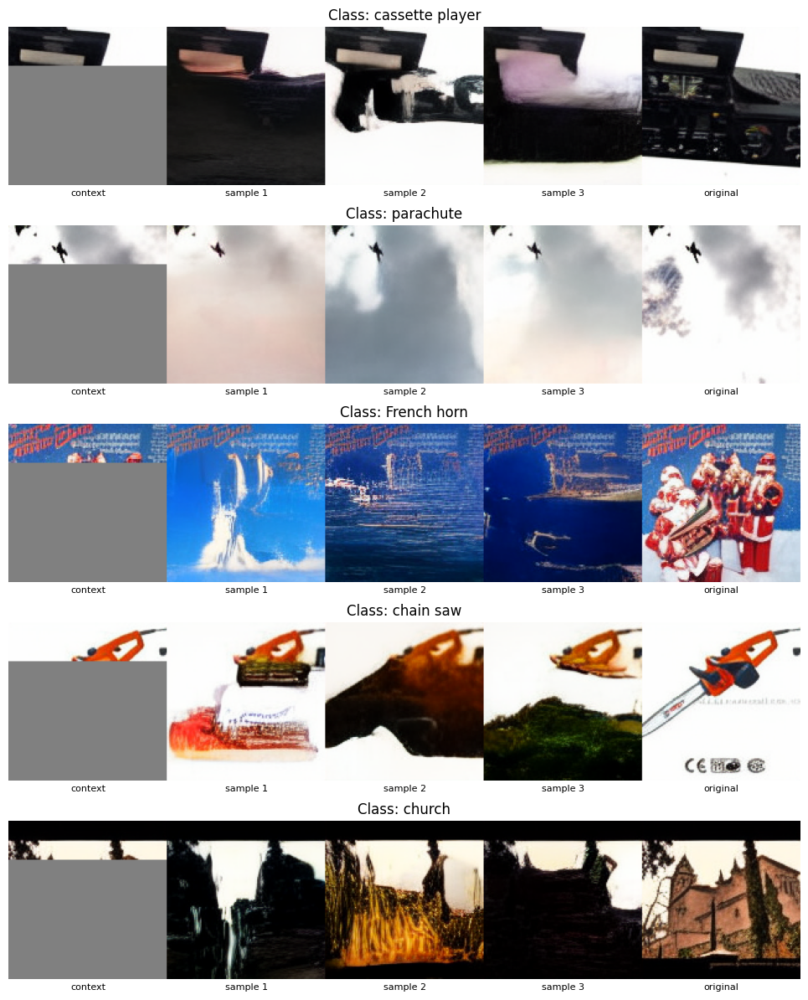

In [61]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=64, temperature=1.0, top_k=1000, device=device,
)

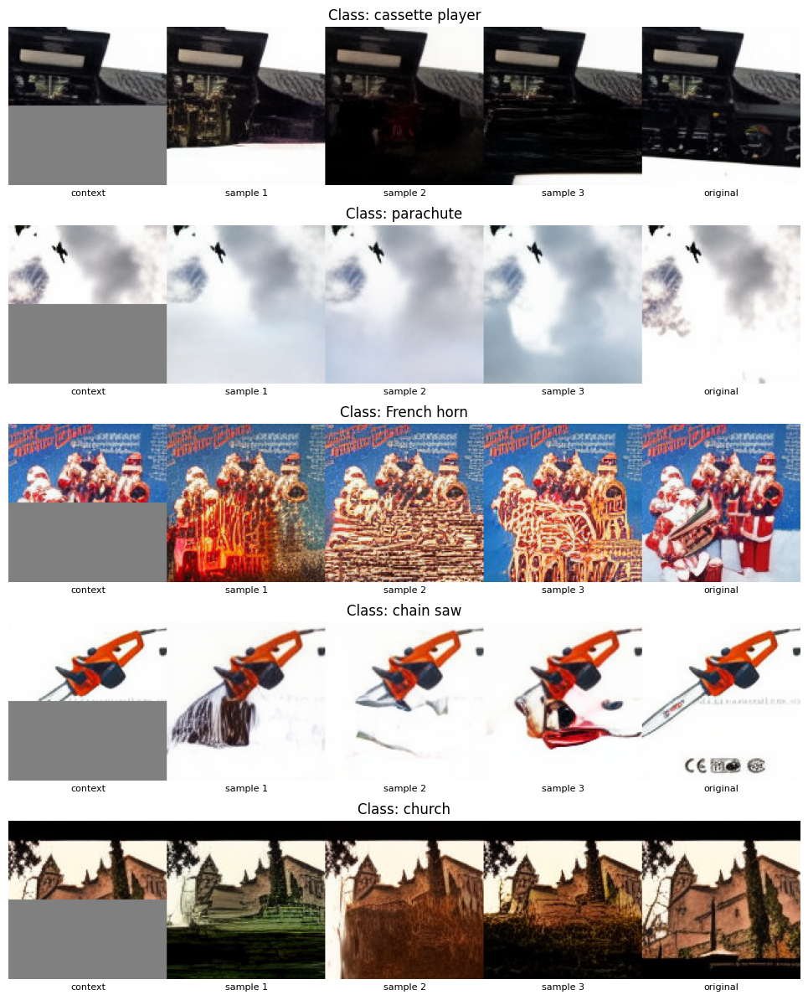

In [62]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=1.0, top_k=1000, device=device,
)

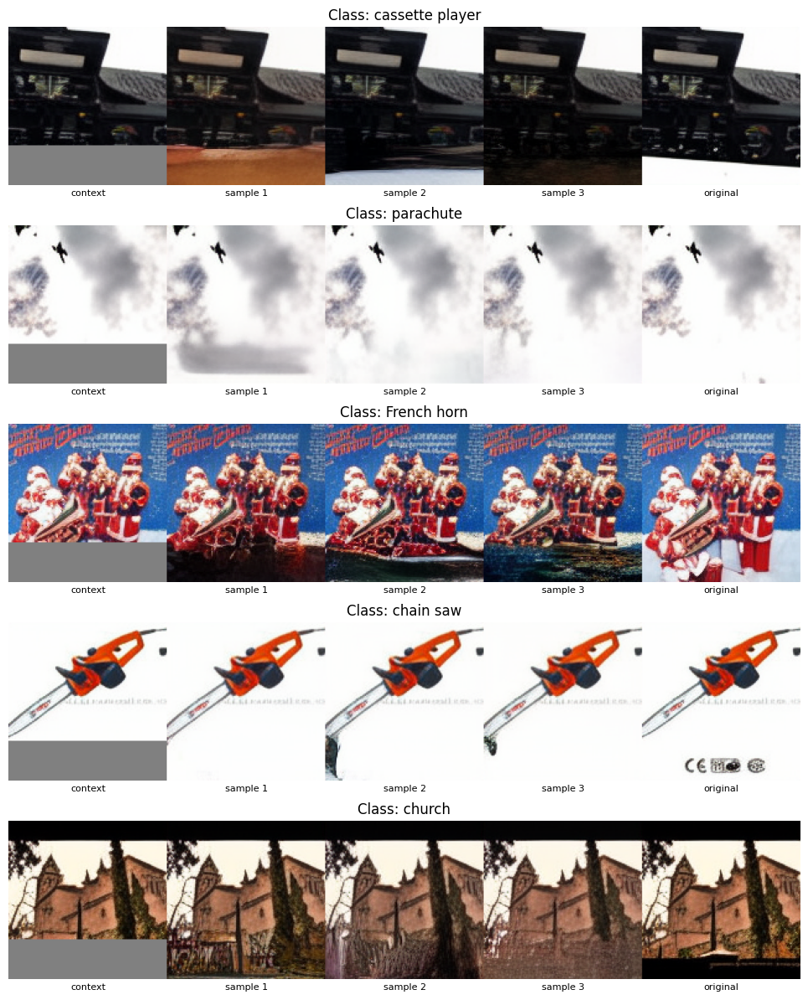

In [63]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=192, temperature=1.0, top_k=1000, device=device,
)

**Ваш ответ:**

При context_size=64 модель видит только верхнюю четверть изображения, поэтому продолжения сильно различаются -- у бензопилы появляются посторонние формы, а на месте церкви получаются довольно разные тёмные и жёлтые текстуры

При context_size=128 общий вид уже ближе к оригиналу, например у церкви продолжаются цвета и линии фасада, но нижняя часть всё ещё часто распадается на полосы или большие пятна

При context_size=192 результат визуально ближе всего к оригиналу -- у бензопилы остаётся почти всё изображение, у церкви модель достраивает только нижнюю часть, а варианты отличаются меньше

Тут важно, что при большом контексте большая часть токенов уже известна, поэтому близость всей картинки к оригиналу сама по себе не доказывает идеальное качество генерации -- восстановить точную нижнюю часть модель всё равно не всегда может

#### Задание 8.2: Температура

Теперь исследуем влияние температуры на качество и разнообразие изображений.

Запустите функцию `generate_and_plot_variations` три раза, используя одинаковый размер контекста `context_size=128` и `top_k=1000`, но с разными значениями температуры `temperature = {0.9, 0.7, 0.5}`. Посмотрите на результаты и сделайте выводы.

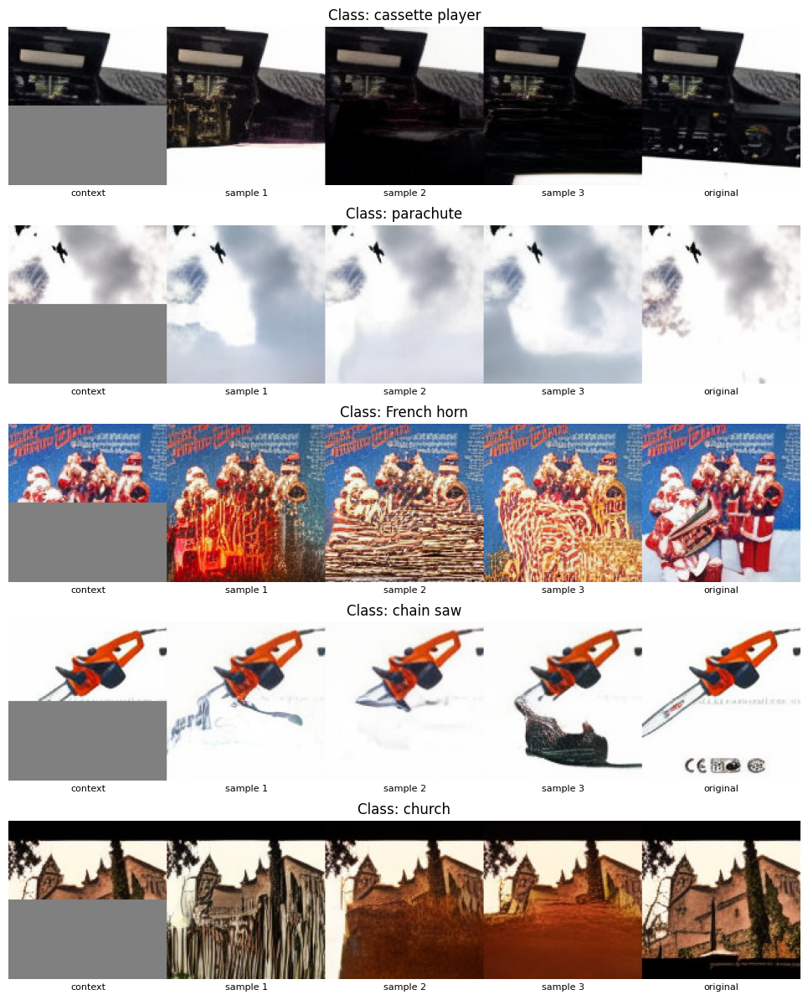

In [64]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=0.9, top_k=1000, device=device,
)

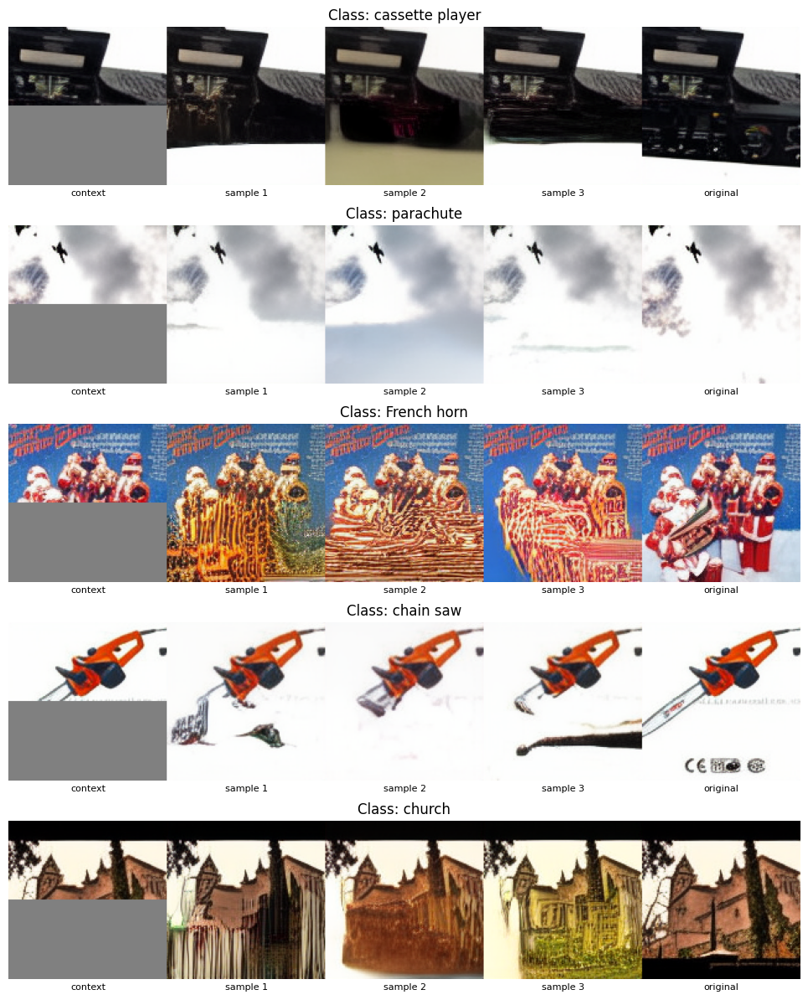

In [65]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=0.7, top_k=1000, device=device,
)

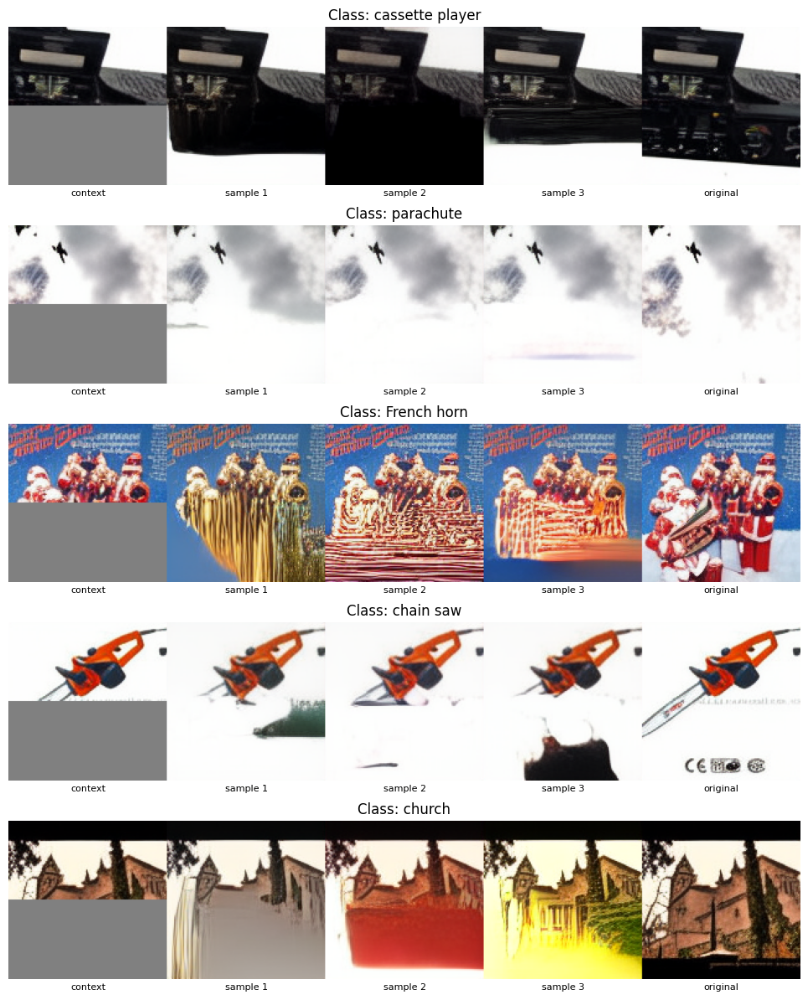

In [66]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=0.5, top_k=1000, device=device,
)

**Ваш ответ:**

При temperature=0.9 продолжения получаются более разнообразными по цветам и текстурам, но встречаются лишние детали -- например внизу изображения бензопилы

При temperature=0.7 детали немного упрощаются, хотя варианты всё ещё заметно отличаются друг от друга, у церкви и изображения с музыкальным инструментом остаются повторяющиеся полосы

При temperature=0.5 чаще появляются большие однотонные области -- у кассетного плеера чёрный низ, у парашюта почти белый фон, у церкви гладкие цветные пятна, поэтому снижение температуры не сделало все изображения лучше

Температура делит логиты перед softmax, при её уменьшении распределение становится более сосредоточенным на вероятных токенах -- на рассмотренных пяти примерах 0.7 визуально выглядит приемлемым компромиссом, но искажения остаются, а универсально оптимальную температуру по этим примерам выбрать нельзя

#### Задание 8.3: Top-k

Наконец, посмотрим на `top_k`.

Запустите функцию `generate_and_plot_variations` три раза с `context_size=128` и `temperature=1.0`, но с разными значениями `top_k = {50, 500, None}`. Значение `None` означает, что отсечения нет и модель выбирает из всех $4096$ токенов словаря.

Сравните, как `top_k` влияет на связность картинки и на разнообразие вариантов, и подумайте, чем этот эффект отличается от того, что даёт температура.

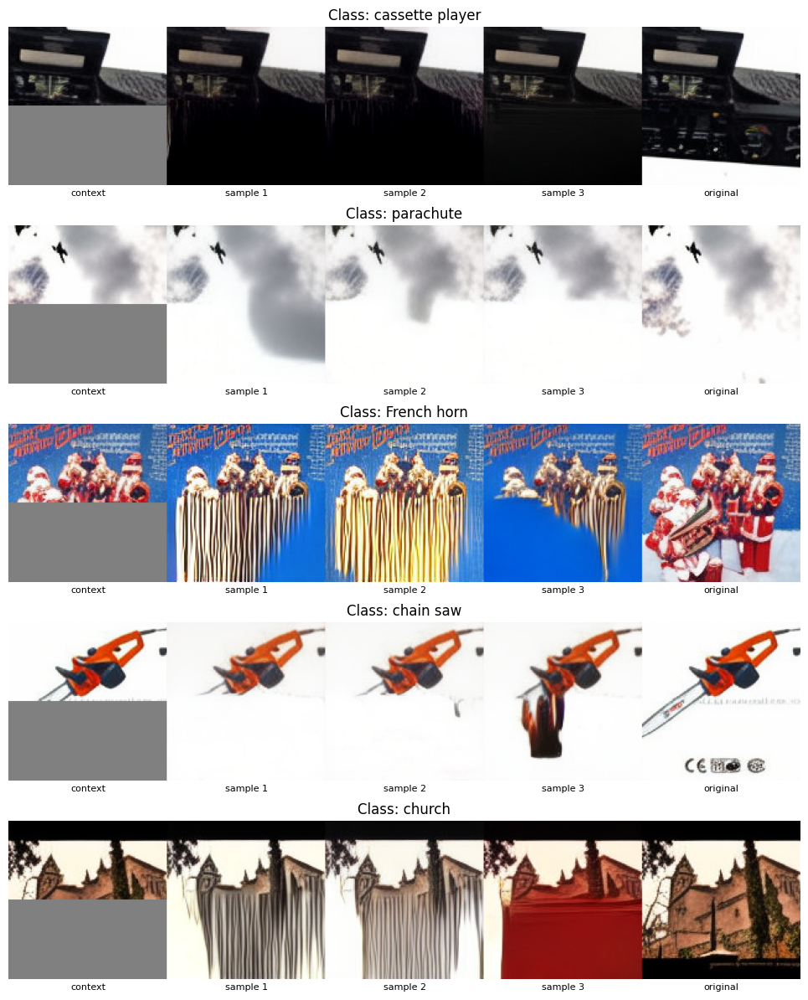

In [67]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=1.0, top_k=50, device=device,
)

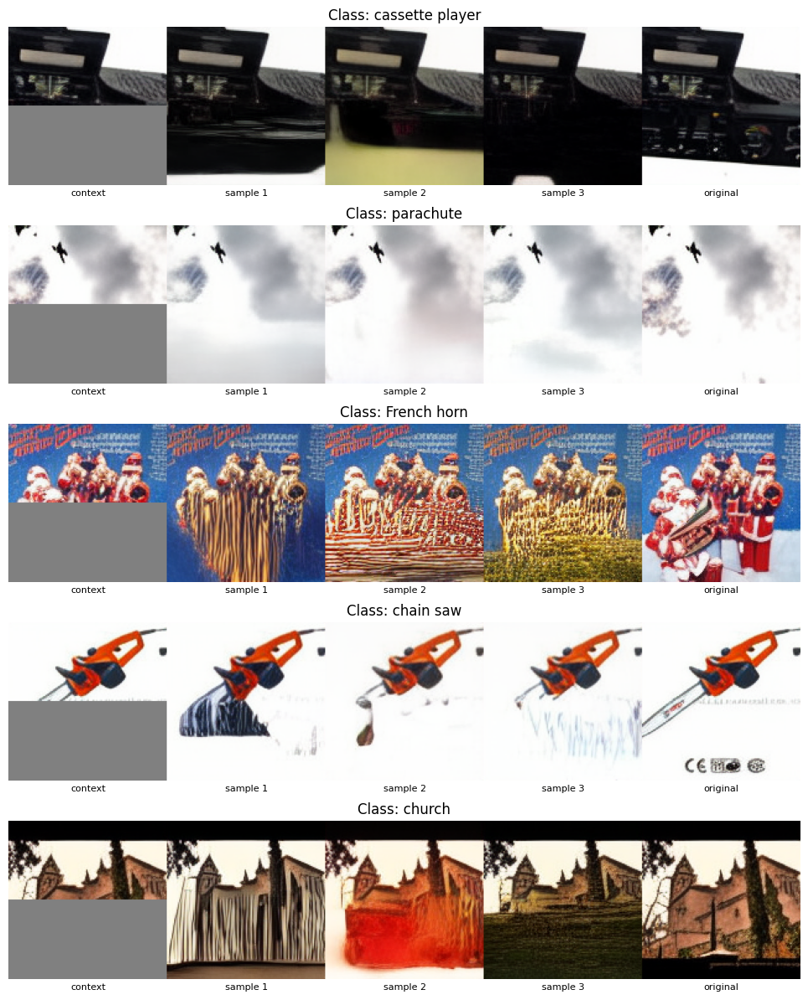

In [68]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=1.0, top_k=500, device=device,
)

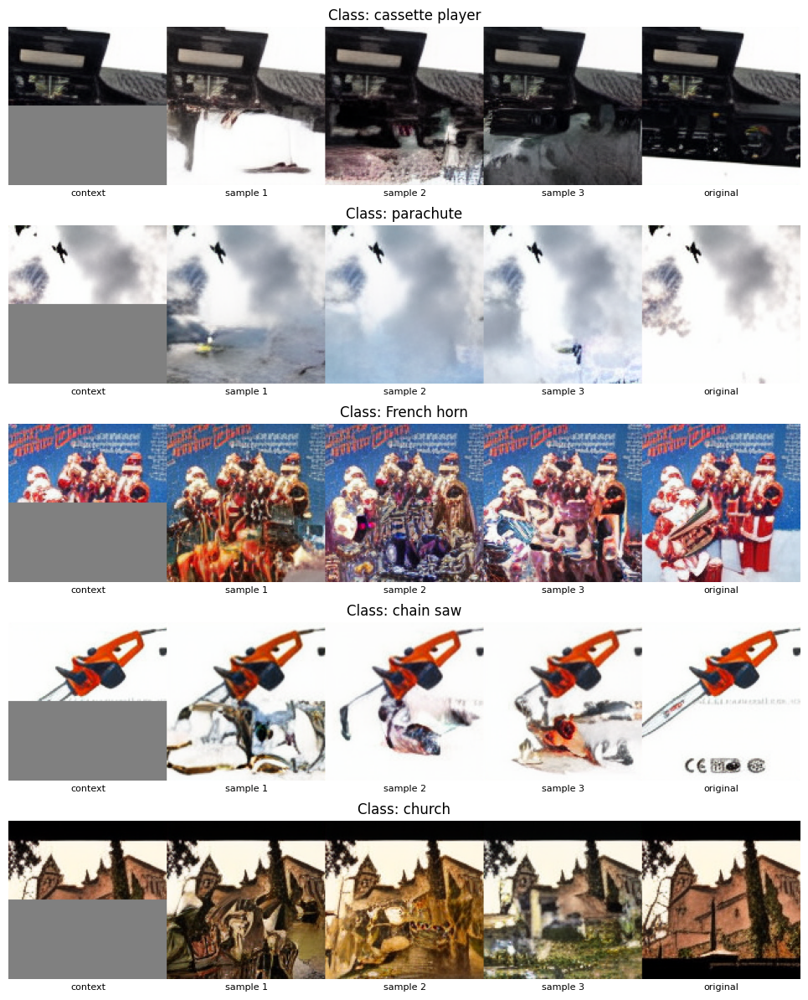

In [69]:
#╰( ͡° ͜ʖ ͡°)つ──☆*:・ﾟ 
# Your code here
torch.manual_seed(123)
generate_and_plot_variations(
    model, vqvae, val_loader, num_contexts=5, samples_per_context=3,
    context_size=128, temperature=1.0, top_k=None, device=device,
)

**Ваш ответ:**

При top_k=50 у модели мало вариантов на каждом шаге, поэтому чаще появляются одинаковые текстуры -- особенно хорошо это видно по длинным вертикальным полосам у музыкального инструмента и церкви, низ кассетного плеера почти во всех вариантах чёрный

При top_k=500 становится больше разных деталей и цветов, хотя полосы и ошибки формы никуда полностью не исчезают

При top_k=None разнообразие самое заметное -- появляются новые формы и мелкие фрагменты, но продолжения становятся менее связными, например под бензопилой возникают посторонние предметы, а нижняя часть церкви сильно искажается

Top-k полностью убирает токены за пределами первых k, а температура меняет соотношение вероятностей среди оставшихся токенов -- маленький k и низкая температура могут оба уменьшать разнообразие, но это разные способы управления выбором

На рассмотренных пяти примерах top_k=500 визуально выглядит приемлемым компромиссом между разнообразием и связностью -- это субъективная оценка небольшой подборки, а не доказательство оптимальности этой настройки

In [70]:
# Здесь можно оставить отзывы, пожелания и впечатления о ДЗ :)